In [2]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"  # Es. sahiljit
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)
    
    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt
    
    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

 [OK] Ambiente rilevato: Locale
 [OK] Directory di lavoro impostata a: /home/matteo/Documents/GitHub/Weather_forecasting


# Neural Network

Hi, I'm a Neural Network.

Hi a Neural Network, we are Singh and Matteo. Before the actual code, it might be helpful define the task we need to overcome in this notebook: finding two values, one for the temperature, one for the precipitations. As we've already told multiple times in the previous notebooks, this will be a regression task, which can be later transformed into a classification one to forecast precipiations. 

Let's consider this firstly. We've seen during our tests that the linear regression works pretty well for the temperature part. This was expected, because Italy, without climate change, has a normal climate behavior, which means summer hot winter cold: this means that by adding features that keep track of climate change and seasonality we can have a good predictor for the temperature. This does not apply to precipitations: both linear regression and SVR could not beat the ludicrous approach of saying "it won't rain" at every prediction. 
This brought us to the decision of skipping the "single" models and to start directly defining a model which can keep track of both temperature and precipitations. 

This decision is fundamental, since it affects deeply the neural network structure. We'll need 60 output neurons!

We'll also need a new ally: Keras.


In [ ]:
import tensorflow as tf

import ctypes, glob, sys
# Use local gpu
for lib in glob.glob(f"{sys.prefix}/lib/python3*/site-packages/nvidia/cusolver/lib/libcusolver.so.11"):
    ctypes.CDLL(lib)

import numpy as np
import pandas as pd
import optuna
import keras
import tensorflow as tf
from keras import layers
from sklearn.preprocessing import StandardScaler
import src.utils.metrics as metrics
from src.data.preprocessing import get_joint_data

print("GPU:", tf.config.list_physical_devices("GPU"))

/home/matteo/Documents/GitHub/Weather_forecasting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
(X_train, y_train), (X_val, y_val), (X_test, y_test) = get_joint_data(t2m_lags=2, tp_lags=2)

x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.values)  # each of the 60 target columns -> mean 0, std 1

Xtr = x_scaler.transform(X_train).astype("float32")
Xva = x_scaler.transform(X_val).astype("float32")
ytr = y_scaler.transform(y_train.values).astype("float32")
yva = y_scaler.transform(y_val.values).astype("float32")

print("inputs:", Xtr.shape[1], "| outputs:", ytr.shape[1])  # e.g. 28 inputs, 60 outputs

inputs: 26 | outputs: 60


In [6]:
def build_model(n_inputs, n_outputs, units, dropout, lr, momentum):
    model = keras.Sequential([keras.Input(shape=(n_inputs,))])
    for u in units:                                   # one entry per hidden layer
        model.add(layers.Dense(u, activation="relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(n_outputs))                # 60 outputs, linear
    model.compile(
        optimizer=keras.optimizers.SGD(learning_rate=lr, momentum=momentum, nesterov=True,
                                       clipnorm=1.0),  # clipnorm: protects against a too-large lr
        loss="mae",
        metrics=["mse"],
    )
    return model


def predict_nn(model, X, y_like):
    pred = model.predict(x_scaler.transform(X).astype("float32"), verbose=0)
    pred = pd.DataFrame(y_scaler.inverse_transform(pred), index=y_like.index, columns=y_like.columns)
    pred["tp_mm"] = pred["tp_mm"].clip(lower=0)  # rain >= 0
    return pred


def joint_score(y_true, pred):
    """Same score as the SVR study: MAE of each column / its std, averaged over the 60 columns."""
    mae = (y_true - pred).abs().mean()
    return (mae / y_train.std()).mean(), mae


class OptunaPruning(keras.callbacks.Callback):
    """Reports val_loss to Optuna after every epoch and stops trials that are clearly worse."""
    def __init__(self, trial):
        super().__init__()
        self.trial = trial

    def on_epoch_end(self, epoch, logs=None):
        self.trial.report(logs["val_loss"], step=epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()

In [7]:
def objective(trial):
    units = []
    for i in range(1, 4):  # 3 hidden layers, each with its own size
        units.append(trial.suggest_int(f"units_{i}", 16, 256, log=True))
    dropout    = trial.suggest_float("dropout", 0.0, 0.5)
    lr         = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    momentum   = trial.suggest_float("momentum", 0.8, 0.99)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128, 256])

    keras.backend.clear_session()  # free the previous trial's model
    keras.utils.set_random_seed(0)  # same starting weights for every trial: fairer comparison
    model = build_model(Xtr.shape[1], ytr.shape[1], units, dropout, lr, momentum)
    model.fit(
        Xtr, ytr,
        validation_data=(Xva, yva),
        epochs=300, batch_size=batch_size, verbose=0,
        callbacks=[
            keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True),
            OptunaPruning(trial),
        ],
    )

    score, mae = joint_score(y_val, predict_nn(model, X_val, y_val))
    trial.set_user_attr("val_mae_t2m", float(mae["t2m_mean"].mean()))
    trial.set_user_attr("val_mae_tp", float(mae["tp_mm"].mean()))
    return score

In [8]:
study = optuna.create_study(
    study_name="joint_nn",
    storage="sqlite:///optuna_joint_nn.db",
    load_if_exists=True,
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=0),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=10),
)
study.optimize(objective, n_trials=40, timeout=60 * 60)

print("Best score:", study.best_value)
print("Best params:", study.best_params)
display(study.trials_dataframe().sort_values("value").head(10))

[I 2026-11-27 19:04:26,558] A new study created in RDB with name: joint_nn
I0000 00:00:1795802667.315229   32939 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5525 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:0b:00.0, compute capability: 8.9
I0000 00:00:1795802669.474659   33782 service.cc:153] XLA service 0x7cb46402fb20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795802669.474673   33782 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795802669.606423   33782 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795802669.867548   33782 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795802669.937012   33782 dot_merger.cc:481] Merging Dots in computation: a_inference_on

Best score: 0.3438727532771397
Best params: {'units_1': 16, 'units_2': 135, 'units_3': 165, 'dropout': 0.015994276622479927, 'lr': 0.06646453099094991, 'momentum': 0.9288505719934128, 'batch_size': 256}


,number,value,datetime_start,datetime_complete,duration,params_batch_size,params_dropout,params_lr,params_momentum,params_units_1,params_units_2,params_units_3,user_attrs_val_mae_t2m,user_attrs_val_mae_tp,system_attrs_tpe:relative_params:0,state
39,39,0.343873,2026-11-27 19:23:20.491024,2026-11-27 19:23:41.493286,0 days 00:00:21.002262,256,0.015994,0.066465,0.928851,16,135,165,2.050903,1.527405,"{""batch_size"": 256, ""dropout"": 0.0159942766224...",COMPLETE
13,13,0.345277,2026-11-27 19:14:46.030789,2026-11-27 19:15:10.978327,0 days 00:00:24.947538,256,0.032792,0.036503,0.870630,31,216,241,2.068520,1.529259,"{""batch_size"": 256, ""dropout"": 0.0327915828914...",COMPLETE
14,14,0.345674,2026-11-27 19:15:10.992467,2026-11-27 19:15:32.665446,0 days 00:00:21.672979,256,0.030459,0.036512,0.858502,29,199,215,2.071512,1.530728,"{""batch_size"": 256, ""dropout"": 0.0304594356329...",COMPLETE
31,31,0.345843,2026-11-27 19:20:58.584689,2026-11-27 19:21:21.762150,0 days 00:00:23.177461,256,0.019767,0.027356,0.901407,24,159,214,2.073795,1.530878,"{""batch_size"": 256, ""dropout"": 0.0197672099559...",COMPLETE
35,35,0.346085,2026-11-27 19:22:10.344697,2026-11-27 19:22:31.987627,0 days 00:00:21.642930,256,0.033079,0.049012,0.895291,30,138,203,2.083895,1.527845,"{""batch_size"": 256, ""dropout"": 0.0330786612688...",COMPLETE
20,20,0.346411,2026-11-27 19:17:18.966553,2026-11-27 19:17:52.433396,0 days 00:00:33.466843,256,0.000936,0.031209,0.856345,48,133,119,2.087126,1.528688,"{""batch_size"": 256, ""dropout"": 0.0009358507949...",COMPLETE
18,18,0.346592,2026-11-27 19:16:34.974244,2026-11-27 19:16:57.382629,0 days 00:00:22.408385,256,0.058259,0.096074,0.843914,91,135,82,2.089914,1.528682,"{""batch_size"": 256, ""dropout"": 0.0582594682813...",COMPLETE
37,37,0.346746,2026-11-27 19:22:48.798630,2026-11-27 19:23:06.153108,0 days 00:00:17.354478,256,0.006563,0.089064,0.841801,26,169,199,2.089994,1.529763,"{""batch_size"": 256, ""dropout"": 0.0065626704312...",COMPLETE
34,34,0.346784,2026-11-27 19:21:49.091053,2026-11-27 19:22:10.335198,0 days 00:00:21.244145,256,0.006174,0.041263,0.892055,23,229,183,2.092672,1.528770,"{""batch_size"": 256, ""dropout"": 0.0061743237370...",COMPLETE
21,21,0.346826,2026-11-27 19:17:52.443231,2026-11-27 19:18:23.255353,0 days 00:00:30.812122,256,0.045395,0.048367,0.834740,41,103,131,2.094465,1.528224,"{""batch_size"": 256, ""dropout"": 0.0453945831033...",COMPLETE


I0000 00:00:1795803897.127280   33779 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1623290__.20
I0000 00:00:1795803898.949889   33782 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1623290__.20
I0000 00:00:1795803908.514683   33779 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1795803909.904774   33783 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


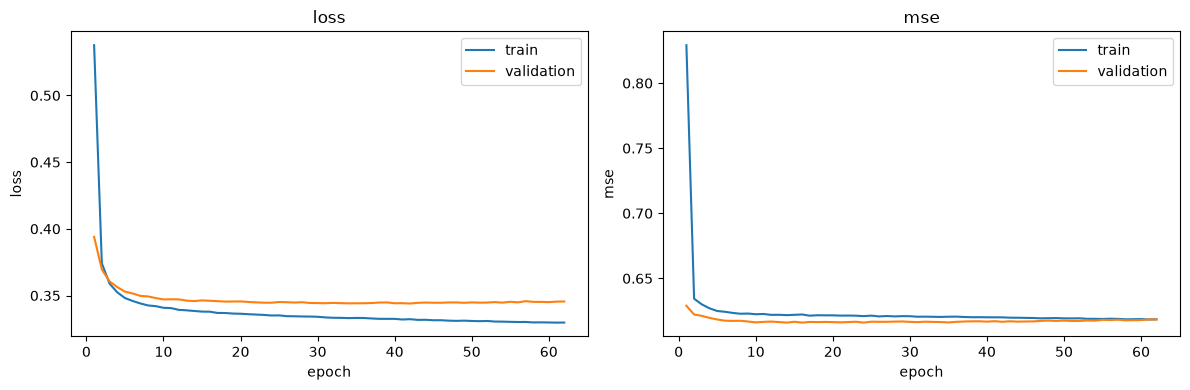

In [9]:
bp = study.best_params
keras.backend.clear_session()
keras.utils.set_random_seed(0)
model = build_model(Xtr.shape[1], ytr.shape[1], [bp["units_1"], bp["units_2"], bp["units_3"]],
                    bp["dropout"], bp["lr"], bp["momentum"])
history = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=300, batch_size=bp["batch_size"],
                    verbose=0, callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)])
metrics.plot_training_history(history, metric="mse")

y_train_pred = predict_nn(model, X_train, y_train)
y_val_pred   = predict_nn(model, X_val, y_val)
y_test_pred  = predict_nn(model, X_test, y_test)